In [3]:
%pip install pandas
%pip install numpy
%pip install matplotlib
%pip install scikit-learn
%pip install progress
%pip install scikit-bio

%git clone https://github.com/RV2005/archetypes
%pip install "archetypes/"

  Using cached pandas-2.2.3-cp311-cp311-win_amd64.whl.metadata (19 kB)
Using cached pandas-2.2.3-cp311-cp311-win_amd64.whl (11.6 MB)
   ---------------------------------------- 0.0/12.9 MB ? eta -:--:--
   --- ------------------------------------ 1.0/12.9 MB 5.6 MB/s eta 0:00:03
   ------ --------------------------------- 2.1/12.9 MB 5.6 MB/s eta 0:00:02
   -------- ------------------------------- 2.9/12.9 MB 4.8 MB/s eta 0:00:03
   ---------- ----------------------------- 3.4/12.9 MB 4.3 MB/s eta 0:00:03
   ------------- -------------------------- 4.5/12.9 MB 4.3 MB/s eta 0:00:02
   ---------------- ----------------------- 5.2/12.9 MB 4.2 MB/s eta 0:00:02
   ------------------- -------------------- 6.3/12.9 MB 4.3 MB/s eta 0:00:02
   ---------------------- ----------------- 7.3/12.9 MB 4.4 MB/s eta 0:00:02
   ------------------------- -------------- 8.4/12.9 MB 4.6 MB/s eta 0:00:01
   ------------------------------ --------- 9.7/12.9 MB 4.8 MB/s eta 0:00:01
   ------------------------

UsageError: Line magic function `%git` not found.


In [2]:
import pandas as pd
import numpy as np
from tqdm import tqdm
import time
import sklearn
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import os

from archetypes import AA
from archetypes.visualization import stacked_bar, simplex
from archetypes.datasets import sort_by_archetype_similarity, permute_dataset
import json

## Performing AA

### Loading Dataset
Change the Directories below to reflect your file structure. 
All data must be in .tsv files under "datasets/tsv" folder

In [3]:
dataDir = os.path.join("datasets", "tsv")
outDir = r"results"

otuFile = "hadza_otu_nov.tsv"
taxFile = "hadza_tax_nov.tsv"

otu = pd.read_table(os.path.join(dataDir, otuFile), index_col=0)
tax = pd.read_table(os.path.join(dataDir, taxFile), index_col=0)

In [4]:
FRAC = 0.1 # Amount of data to sample
otu_sample = otu.sample(frac=FRAC)

### Grouping the OTU columns by Taxonomic Level
This is equivalent to tax_glom() in R. <br>
Change the 'group' variable to vary the level w.r.t to the dataset (some of the available levels are listed for the hadza dataset)

In [5]:
# ------tax_glom() equivalent------

group = "Genus" # Change this to "Kingdom", "Phylum", "Class", "Order", "Family", "Genus",to group by that taxonomic level

# No of uniques => {Kingdom: 1, Phylum: 15, Class: 25, Order: 44, Family: 77, Genus: 305}

grouped_cols = tax[group].unique()

otu_grouped = pd.DataFrame(index=otu_sample.index, columns=grouped_cols)

i = 0
for c in tqdm(otu_sample.columns):
    grp_col = tax[group][c]
    
    if(pd.isnull(otu_grouped[grp_col]).all()):
        otu_grouped[grp_col] = otu_sample[c]
        continue

    otu_grouped[grp_col] = otu_grouped[grp_col] + otu_sample[c]
    # print(f"Processed column ({i+1}/{len(otu.columns)}): {grp_col}")

    i += 1

otu_grouped.columns = otu_grouped.columns.astype(str)


100%|██████████| 2647/2647 [00:00<00:00, 3538.74it/s]


### Log Transforming

In [6]:
otu_log = otu_grouped.copy()
otu_log = otu_log.map(lambda x: np.log2(x+1))

### PCoA Implementation
You can change the 'method' variable to change what distance metric you want to use. <br>
Available options are "jensenshannon" and "braycurtis" for now

c:\Users\rayve\.conda\envs\testAA\Lib\site-packages\skbio\stats\ordination\_principal_coordinate_analysis.py:214: RuntimeWarning: The result contains negative eigenvalues that are large in magnitude, which may suggest result inaccuracy. See Notes for details. The negative-most eigenvalue is -1.4044039118310494 whereas the largest positive one is 97.81466071788292.
  warn(


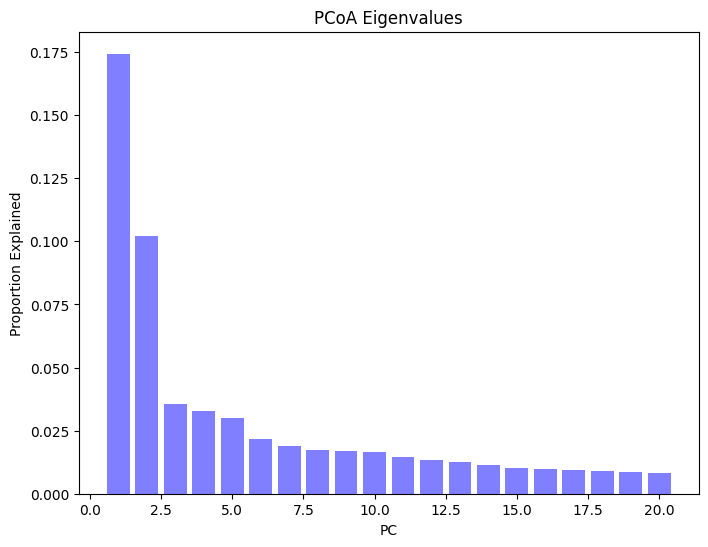

In [7]:
import scipy.spatial
from skbio.tree import TreeNode
from skbio.diversity import beta_diversity
from skbio.stats.ordination import pcoa
import scipy

method = 'braycurtis'  #'jensenshannon' or 'bray_curtis', unifrac is problematic


pcoa_data = otu_log.copy()

method = scipy.spatial.distance.jensenshannon if method == 'jensenshannon' else method 

bdiv = beta_diversity(
    method, pcoa_data, ids=pcoa_data.index, pairwise_func=scipy.spatial.distance.pdist
)
# Perform PCoA
pcoa_results = pcoa(bdiv, number_of_dimensions=20)

# Plot the PCoA Eigenvalues and proportions explained

fig, ax = plt.subplots(1, 1, figsize=(8, 6))
ax.bar(range(1, len(pcoa_results.eigvals) + 1), pcoa_results.proportion_explained, color="blue", alpha=0.5, align="center")
ax.set_xlabel("PC")
ax.set_ylabel("Proportion Explained")
ax.set_title("PCoA Eigenvalues")
plt.show()



### Archetypal Analysis
Choose the number of PCs to perform AA on. This will choose the top n PCs from the graph above

In [8]:
NUM_PC = 5
# Extract the coordinates
pcoa_coordinates = pcoa_results.samples[[f"PC{i}" for i in range(1, NUM_PC+1)]]

In [12]:
# from archetypes.numpy._aa_3 import AA_3
from archetypes import AA

AA_data = pcoa_coordinates.to_numpy()

method_kwargs = {
    "max_iter_optimizer": 10,
}

N_ARCHETYPES = 4
aa = AA(n_archetypes=N_ARCHETYPES, method="pgd", method_kwargs=method_kwargs, random_state=3)


aa.fit(AA_data)
data_sorted, info = sort_by_archetype_similarity(AA_data, [aa.similarity_degree_], aa.archetypes_)

print(aa.archetypes_)

c:\Users\rayve\.conda\envs\testAA\Lib\site-packages\sklearn\base.py:474: FutureWarning: `BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.
  warnings.warn(


[[ 0.51201152 -0.08093396  0.06431109  0.07047833  0.11775036]
 [-0.04616659 -0.39814825 -0.09858499 -0.08808614 -0.12653791]
 [-0.35211081 -0.03381778  0.09580168  0.08602454  0.13332448]
 [-0.02086015  0.31545699 -0.06369459 -0.05207097 -0.09833916]]


### Saving the Results
The results are saved in the format: 
`results/otu_AA_<NUM_ARCHS>_<FRAC>_<group>_<methodName>.json`. <br>
For example `results/otu_AA_K3_1.0_Genus_braycurtis.json`

In [13]:
otu_aa = pd.DataFrame(aa.similarity_degree_, index=pcoa_coordinates.index, columns=[f"Archetype {i+1}" for i in range(N_ARCHETYPES)])

# Make a json file containing all details for the archetypes
import json
aa_dict = {
        "archetypes": aa.archetypes_.tolist(),
        "similarity_degree": aa.similarity_degree_.tolist(),
        "labels": aa.labels_.tolist(), 
        "index": pcoa_coordinates.index.tolist(),
        "columns": [f"Archetype {i+1}" for i in range(N_ARCHETYPES)], 
        "loss": aa.loss_,
        "info_perms": info["perms"][0].tolist(),
        "info_scores": info["scores"][0].tolist(),
        "info_alphas": info["alphas"][0].tolist(),
        "dataCols": grouped_cols.tolist()
}


In [14]:
methodName = method if isinstance(method, str) else "jensenshannon"

outName = f"otu_AA_K{N_ARCHETYPES}_{FRAC}_{group}_{methodName}_{NUM_PC}.json"
outPath = os.path.join(outDir, outName)

json.dump(aa_dict, open(outPath, "w"))
# otu_aa.to_csv(outPath, sep="\t")

# Standard Analysis

### Simplex Plotter Utility

In [15]:
### Simplex Plotter
from matplotlib.patches import Patch
import matplotlib.cm as cm


def filter_further(data, further_filter, filter_type): 
    if filter_type == "equals": 
        return data[data.isin(further_filter)]
    elif filter_type == "not_equals":
        return data[~data.isin(further_filter)]
    elif filter_type == "greater_than":
        return data[data > further_filter]
    elif filter_type == "less_than":
        return data[data < further_filter]


def plot_simplex(otu_aa, hadza_sam, filter_cols, 
                cmap_name="tab20", legend_type="discrete", 
                remove_nan=False, further_filter=None, figsize=(15, 15)):
    """ 
    otu_aa: DataFrame
        The archetypal analysis data
    hadza_sam: DataFrame
        The metadata
    filter_cols: list
        The columns to filter the data by (must contain exact column names from metadata)
    cmap_name: str (optional)
        The name of the colormap to use
    legend_type: str (optional)
        The type of legend to use. Can be "discrete" or "continuous"
    remove_nan: bool (optional)
        Whether to remove NaN values from the data
    further_filter: Dict (optional) = {"filter_type": "equals", "value": []}
        Further filter the data by the values in this list
    figsize: tuple (optional)
        The size of the figure
    """

    present_idx = otu_aa.index.intersection(hadza_sam.index)
    present_points = otu_aa.loc[present_idx]

    # Print the number of values dropped
    print(f"Dropped {len(otu_aa) - len(present_points)} data points: Index not found in metadata")

    # For each data point, add the first non-null value from filter_cols to the filter_labels
    filter_labels = pd.Series(index=present_points.index, dtype=str)
    for col in filter_cols:
        filter_labels = filter_labels.fillna(hadza_sam.loc[present_idx, col])

    # If further_filter is not none, filter the dataset by matching values to each further_filter element
    if further_filter is not None:
        present_points = filter_further(present_points, further_filter["filter_type"], further_filter["value"])
        filter_labels = filter_further(filter_labels, further_filter["filter_type"], further_filter["value"])

    if remove_nan:
        nan_idx = filter_labels.index[filter_labels.isnull()]
        present_points = present_points.drop(nan_idx)
        filter_labels = filter_labels.drop(nan_idx)

    if(legend_type == "discrete"):
        unique_colors = {c: i for i, c in enumerate(filter_labels.unique())}
        color = filter_labels.map(unique_colors)

    elif(legend_type == "continuous"):
        unique_colors = filter_labels
        color = filter_labels.astype(float)

    cmap = plt.cm.get_cmap(cmap_name, len(unique_colors))
    fig, ax = plt.subplots(1, 1, figsize=figsize)
    simplex(present_points, alpha=0.5, ax=ax, c=color, cmap = cmap, s=5, vertices_labels=otu_aa.columns)

    def add_discrete_legend(ax, unique_colors, cmap):
        legend_patches = [
            Patch(color=cmap(unique_colors[c]), label=c)
            for c in unique_colors
        ]

        # Add the legend to the plot
        ax.legend(handles=legend_patches, title=filter_cols, loc='upper right')

    def add_continuous_legend(ax, filter_labels, cmap):
        # Add the legend to the plot with appropriate min and max values
        cbar = plt.colorbar(cm.ScalarMappable(cmap=cmap), ax=ax, orientation='vertical')
        cbar.set_label(f"{filter_cols}: min: {str(min(filter_labels))}; max: {str(max(filter_labels))}" )

    if legend_type == "discrete":
        add_discrete_legend(ax, unique_colors, cmap)
    elif legend_type == "continuous":
        add_continuous_legend(ax, filter_labels, cmap)




### Loading the results
Change the paths below according to your file structure

In [16]:
dataDir = "datasets/tsv"

fName = "results\otu_AA_K3_0.1_Genus_braycurtis_5.json" # if outPath is None else outPath
otu_dict = json.load(open(fName, "r"))
otu_aa = pd.DataFrame(otu_dict["similarity_degree"], index=otu_dict["index"], columns=otu_dict["columns"])
aa_labels = np.array(otu_dict["labels"])
aa_archetypes = otu_dict["archetypes"]
info = {
    "perms": otu_dict["info_perms"],
}

samPath = os.path.join(dataDir, "hadza_sam_nov.tsv")

# Create hadza_sam dataframe with index column as SampleID2
hadza_sam = pd.read_table(samPath, index_col=0)

C:\Users\rayve\AppData\Local\Temp\ipykernel_35872\2287199361.py:15: DtypeWarning: Columns (1,3,4,5,6,7,9,10,11,12,13,14,15,16,17,18,19,20,22,24,25,26,27,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,57,58,61,65,66,67,68,69,70,71,72,73,75,76,77,78,79,80,81,82,83,86,87,88,89,90,91,92,95,97,98,100,101,102,103,105,112,113,114,116,118,120,123,134,135,136,137,138,139,140,141,142,143,146,147,148,149,150,154,155,156,159,161,162,165,166,167,168,169,170,171,172,173,174,175,176,177,178,179,180,181,182,183,184,185,186,187,188,189,190,191,192,194,197,198) have mixed types. Specify dtype option on import or set low_memory=False.
  hadza_sam = pd.read_table(samPath, index_col=0)


### Plotting the Simplex Graph

C:\Users\rayve\AppData\Local\Temp\ipykernel_35872\563056466.py:7: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap("tab20", n_archs)


<Axes: >

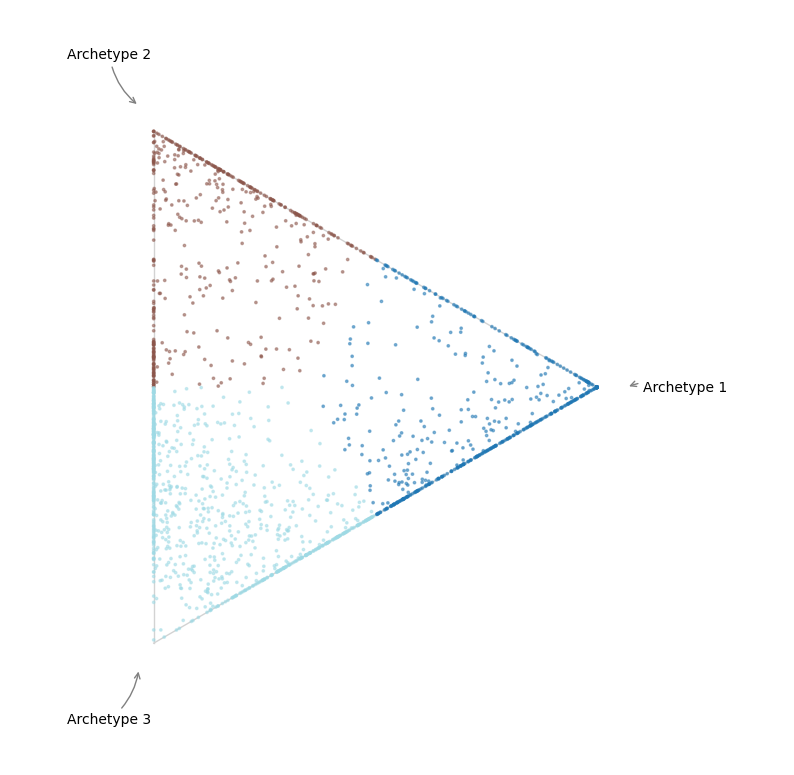

In [17]:
n_archs = len(aa_archetypes)
# Normalize the aa_labels
otu_aa_swapped = otu_aa.copy()

color =  aa_labels

cmap = plt.cm.get_cmap("tab20", n_archs)

fig, ax = plt.subplots(1, 1, figsize=(10, 10))
simplex(otu_aa.to_numpy(), alpha=0.5, ax=ax, c=color, cmap=cmap, s=3, vertices_labels=otu_aa.columns)


### Reordering (optional)
Sometimes the graph is quite messy, with prominent lines going through the middle. <br>
You may find it helpful to reorder the archetypes. This can be done by changing the array below in order
Caution: This depends on how many archetypes there are. You may have to change the ordering for each new result loaded. 

In [18]:
otu_aa_swapped = otu_aa[["Archetype 1", "Archetype 5", "Archetype 8", "Archetype 2", "Archetype 6", "Archetype 7", "Archetype 9", "Archetype 3", "Archetype 4"]]

# otu_aa_swapped = otu_aa
# otu_aa_swapped = otu_aa[["Archetype 1", "Archetype 2", "Archetype 8", "Archetype 7", "Archetype 4" , "Archetype 3", "Archetype 6", "Archetype 9", "Archetype 5", "Archetype 10"]]

KeyError: "['Archetype 5', 'Archetype 8', 'Archetype 6', 'Archetype 7', 'Archetype 9', 'Archetype 4'] not in index"

Plotting the reordered Simplex

C:\Users\rayve\AppData\Local\Temp\ipykernel_26304\3839999831.py:6: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap("tab20", n_archs)


<Axes: >

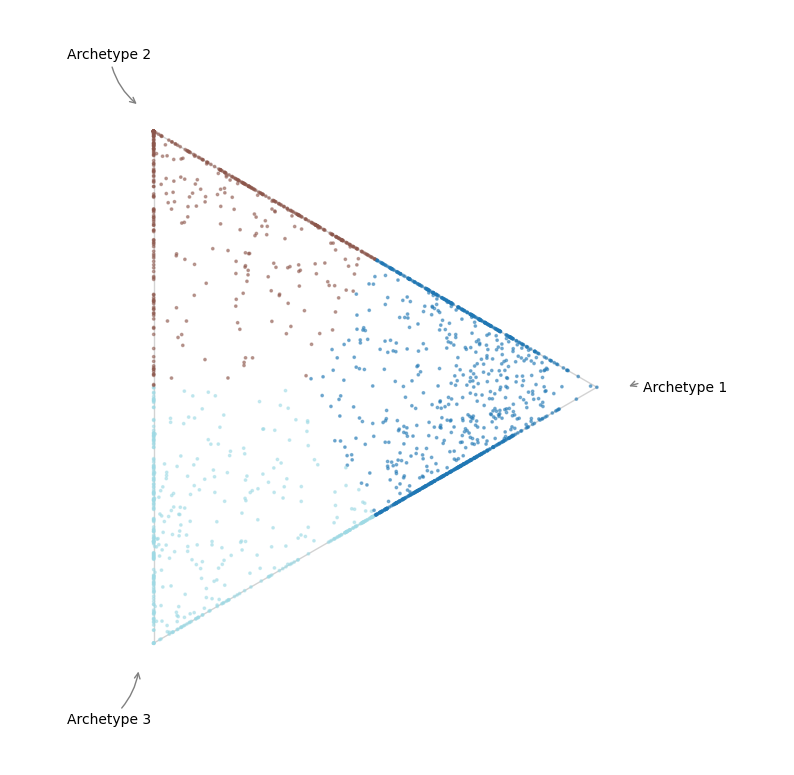

In [32]:
n_archs = len(aa_archetypes)
# Normalize the aa_labels

color =  aa_labels

cmap = plt.cm.get_cmap("tab20", n_archs)

fig, ax = plt.subplots(1, 1, figsize=(10, 10))
simplex(otu_aa_swapped.to_numpy(), alpha=0.5, ax=ax, c=color, cmap=cmap, s=3, vertices_labels=otu_aa_swapped.columns)


## Plotting by Filter with Color
Below is the usage of the plot_simplex() utility for plotting by location. Here, `filter_cols` contains the columns of the sample dataset to filter by. <br>
`legend_type` parameter sets whether the values are "discrete" or "continuous"

Dropped 392 data points: Index not found in metadata


C:\Users\rayve\AppData\Local\Temp\ipykernel_35872\4050953862.py:68: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap(cmap_name, len(unique_colors))


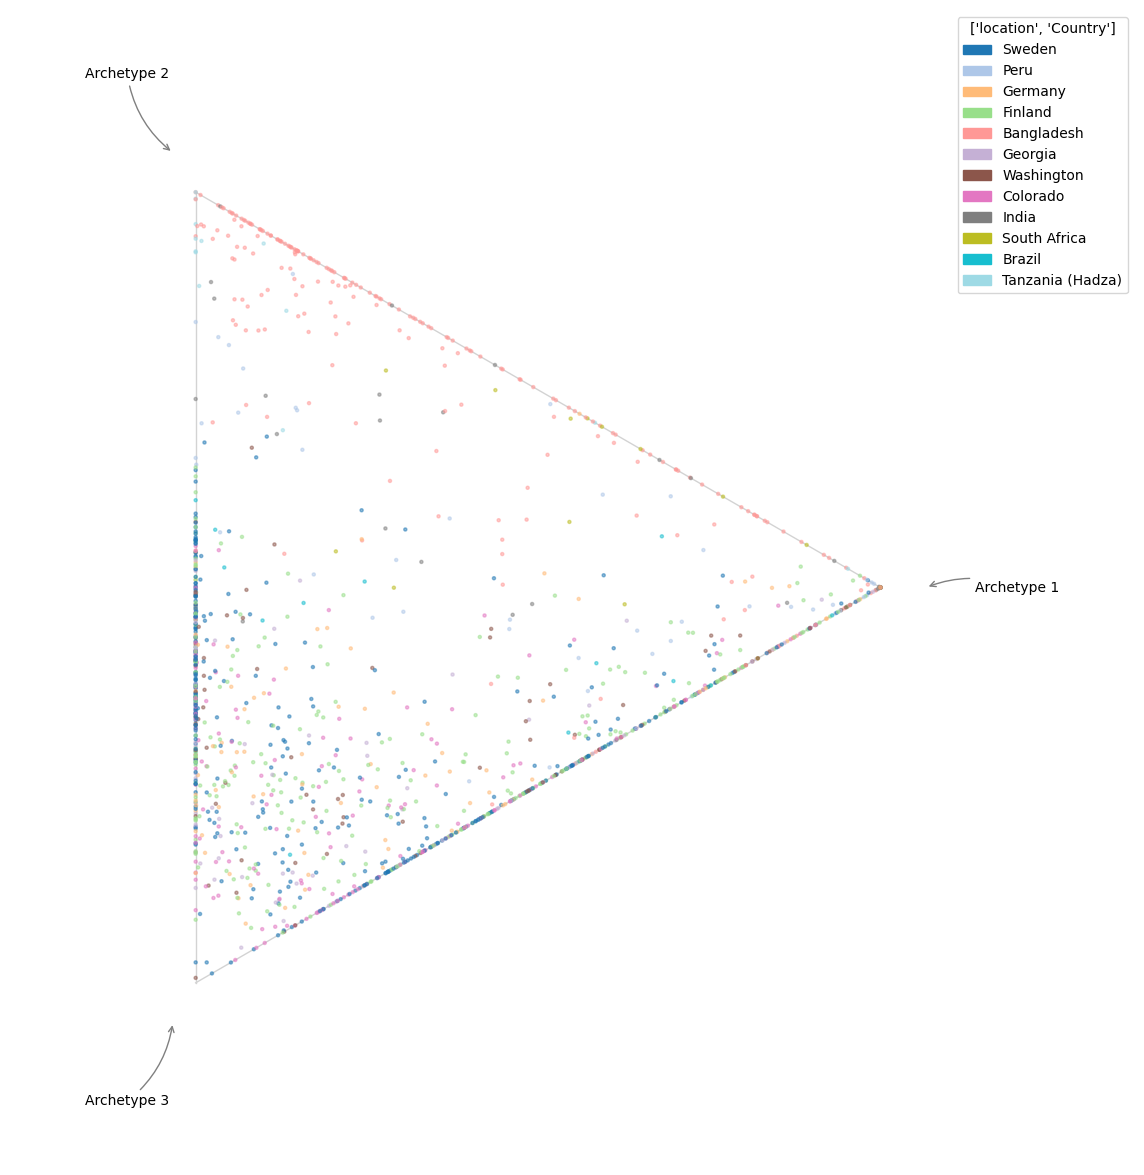

In [19]:
# FOR COUNTRY
filter_cols = ["location", "Country"]

plot_simplex(otu_aa_swapped, hadza_sam, filter_cols, cmap_name="tab20", legend_type="discrete", remove_nan=True)

Similarly, for age. This time, the `legend_type` is "continuous"

Dropped 392 data points: Index not found in metadata


C:\Users\rayve\AppData\Local\Temp\ipykernel_35872\4050953862.py:48: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  filter_labels = filter_labels.fillna(hadza_sam.loc[present_idx, col])
C:\Users\rayve\AppData\Local\Temp\ipykernel_35872\4050953862.py:68: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap(cmap_name, len(unique_colors))


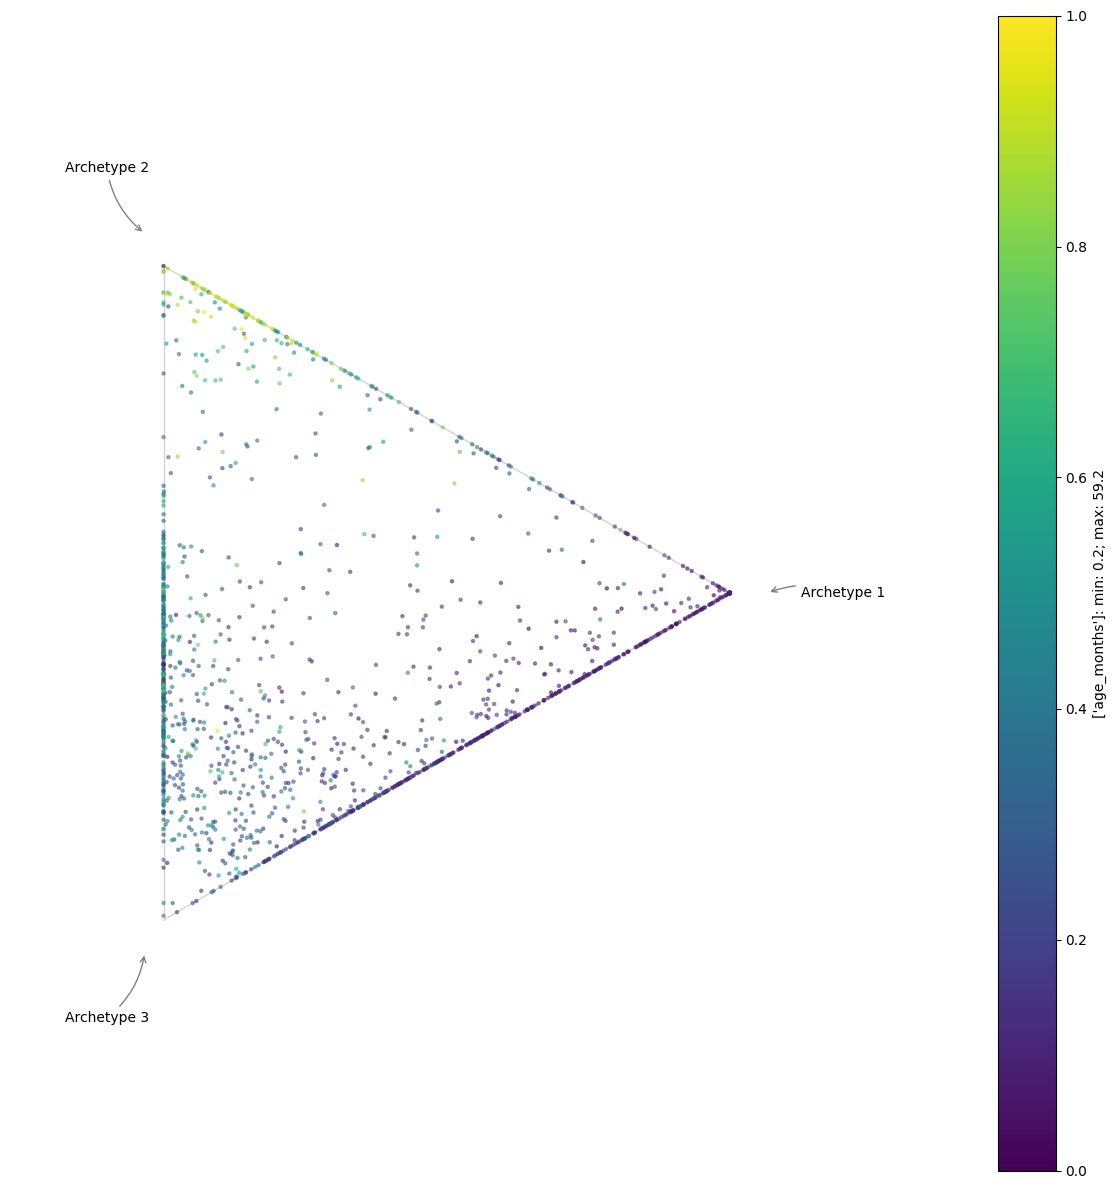

In [20]:
# FOR AGE

plot_simplex(otu_aa_swapped, hadza_sam, ["age_months"], "viridis", "continuous", remove_nan=True)

## Work In Progress: Display Archetype Composition

In [ ]:
dataDir = os.path.join("datasets", "tsv")
outDir = r"results"

otuFile = "hadza_otu_nov.tsv"
taxFile = "hadza_tax_nov.tsv"

otu = pd.read_table(os.path.join(dataDir, otuFile), index_col=0)
tax = pd.read_table(os.path.join(dataDir, taxFile), index_col=0)



: 

In [ ]:
# archs = pd.DataFrame(aa_archetypes, columns=grouped_cols, index=[f"Archetype {i+1}" for i in range(n_archs)])
archs = pd.DataFrame(aa_archetypes, columns=otu.columns, index=[f"Archetype {i+1}" for i in range(n_archs)])

NUM_TAXA = 5

# Extract the top 5 taxa for each archetype

# For each row in archs, sort the values in descending order

tax_sorted_archs = archs.copy()
for i in range(archs.shape[0]):
    tax_sorted_archs.iloc[i] = tax_sorted_archs.iloc[i].sort_values(ascending=False)

# sorted_archs = archs.apply(lambda x: x.sort_values(ascending=False), axis=0)
top_n_taxa_archs = tax_sorted_archs.iloc[:, :NUM_TAXA]

# Go through each top taxa archetype, and find the column from which the value comes from

top_taxa_archs = [] # 2D Tuples (value, taxa)
for i,arch in top_n_taxa_archs.iterrows():
    top_taxa  = []
    for val in arch:
        # Find the column from whi  ch the value comes from in Row i from archs dataframe
        taxa = archs.loc[i][archs.loc[i] == val].index[0]
        top_taxa.append((val, taxa))

    top_taxa_archs.append(top_taxa)


# Find the percentage of each taxon in the archetype w.r.t archs
for i, arch in enumerate(top_taxa_archs):
    total = archs.loc[f"Archetype {i+1}"].sum()
    for j, (val, taxa) in enumerate(arch):
        top_taxa_archs[i][j] = (val/total, taxa)

# For each arch, add a new element ("Others") with the value 1 - sum of all other values
for i, arch in enumerate(top_taxa_archs):
    top_taxa_archs[i].append((1 - sum([val for val, taxa in arch]), "Others"))

# print(top_taxa_archs)

# Make seperate pie charts for each archetype
fig, ax = plt.subplots((n_archs+1) // 2, 2, figsize=(10, 20))
for i, arch in enumerate(top_taxa_archs):
    vals = [val for val, taxa in arch]
    labels = [taxa for val, taxa in arch]

    print(f"**Archetype {i+1}**")
    print()
    for k, label in enumerate(labels):
        print(f"***Label {k+1}***: {label} \n")
    print("\n")
    plotLabels = [f"{i+1}" for i in range(len(labels)-1)] + ["Others"]
    ax[i // 2, i % 2].pie(vals, labels=plotLabels, autopct='%1.1f%%')
    ax[i // 2, i % 2].set_title(f"Archetype {i+1}")

plt.show()



In [ ]:
# Read all json files from /results/SBATCH_N3_N12, and plot the loss vs n_archetypes
import glob
import json

jsonFiles = glob.glob("results/SBATCH_N3_N15_NoPC_NoGlom/*.json")

losses = []

n_archs = [3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]


# Create a dict with keys n_archs and values losses from the appropriate json files
arch_losses = {}

for n in n_archs:
    for j in jsonFiles:
        if f"K{n}_" in j:
            otu_dict = json.load(open(j, "r"))
            arch_losses[n] = otu_dict["loss"][-1]    


plt.plot(arch_losses.keys(), arch_losses.values(), marker="o")
plt.xlabel("Number of Archetypes")
plt.ylabel("Loss")

# Label the losses on the plot up to 3 significant digits
pad = 0.1
for i, txt in enumerate(n_archs):
    plt.annotate(f"{txt}", (n_archs[i] + pad, arch_losses[txt] + pad))

# Plot the smallest loss in green
min_loss = min(arch_losses.values())
min_key = [key for key, value in arch_losses.items() if value == min_loss][0]
plt.scatter(min_key, min_loss, color="red", s=100)

plt.show()



NameError: name 'plt' is not defined